In [7]:
import pandas as pd
import numpy as np

# Load monthly value-weighted returns
data = pd.read_csv(
    "../data/10_Industry_Portfolios.csv",
    skiprows=11,
    nrows=1203,
    index_col=0
)

# Convert columns to numeric values
data = data.apply(pd.to_numeric, errors="coerce")

# Handle missing values
data = data.replace([-99.99, -999], np.nan)
data = data.dropna()

data = data / 100

print(data.head())
print(data.shape)

         NoDur   Durbl   Manuf   Enrgy   HiTec   Telcm   Shops    Hlth  \
192607  0.0144  0.1558  0.0470 -0.0114  0.0290  0.0083  0.0012  0.0185   
192608  0.0399  0.0370  0.0280  0.0343  0.0266  0.0217 -0.0072  0.0417   
192609  0.0115  0.0498  0.0117 -0.0330 -0.0039  0.0242  0.0021  0.0069   
192610 -0.0124 -0.0839 -0.0365 -0.0078 -0.0458 -0.0011 -0.0229 -0.0057   
192611  0.0521 -0.0017  0.0427  0.0001  0.0471  0.0163  0.0645  0.0543   

         Utils   Other  
192607  0.0704  0.0214  
192608 -0.0170  0.0435  
192609  0.0205  0.0031  
192610 -0.0327 -0.0285  
192611  0.0440  0.0213  
(1203, 10)


In [9]:

print("Industries:")
print(data.columns.tolist())


print("\nMissing Values:")
print(data.isnull().sum())

print("\nSummary Statistics:")
print(data.describe())

Industries:
['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'HiTec', 'Telcm', 'Shops', 'Hlth', 'Utils', 'Other']

Missing Values:
NoDur    0
Durbl    0
Manuf    0
Enrgy    0
HiTec    0
Telcm    0
Shops    0
Hlth     0
Utils    0
Other    0
dtype: int64

Summary Statistics:
             NoDur        Durbl        Manuf        Enrgy        HiTec  \
count  1203.000000  1203.000000  1203.000000  1203.000000  1203.000000   
mean      0.009363     0.011706     0.010232     0.010430     0.011738   
std       0.045576     0.082385     0.062038     0.064164     0.071353   
min      -0.249700    -0.348600    -0.300200    -0.344700    -0.339600   
25%      -0.014000    -0.029600    -0.020450    -0.024600    -0.025350   
50%       0.010400     0.009800     0.013500     0.009100     0.013500   
75%       0.035850     0.049600     0.042800     0.045550     0.050800   
max       0.342400     0.797900     0.580800     0.393600     0.518100   

             Telcm        Shops         Hlth        Utils        Other

In [10]:
# Calculate average monthly returns
mu = data.mean()

# Calculate covariance matrix
Sigma = data.cov()

print("Expected Monthly Returns:")
print(mu)

print("\nCovariance Matrix:")
print(Sigma)

Expected Monthly Returns:
NoDur    0.009363
Durbl    0.011706
Manuf    0.010232
Enrgy    0.010430
HiTec    0.011738
Telcm    0.008137
Shops    0.010301
Hlth     0.010692
Utils    0.008761
Other    0.009192
dtype: float64

Covariance Matrix:
          NoDur     Durbl     Manuf     Enrgy     HiTec     Telcm     Shops  \
NoDur  0.002077  0.002521  0.002379  0.001762  0.002328  0.001439  0.002230   
Durbl  0.002521  0.006787  0.004156  0.002894  0.004368  0.002214  0.003606   
Manuf  0.002379  0.004156  0.003849  0.002781  0.003750  0.001948  0.003006   
Enrgy  0.001762  0.002894  0.002781  0.004117  0.002602  0.001555  0.002080   
HiTec  0.002328  0.004368  0.003750  0.002602  0.005091  0.002200  0.003274   
Telcm  0.001439  0.002214  0.001948  0.001555  0.002200  0.002176  0.001794   
Shops  0.002230  0.003606  0.003006  0.002080  0.003274  0.001794  0.003339   
Hlth   0.001971  0.002642  0.002561  0.001887  0.002774  0.001515  0.002330   
Utils  0.001747  0.002495  0.002327  0.002011  0

In [11]:
# Create vector of ones
one = np.ones(len(mu))

# Solve covariance matrix system
Si1 = np.linalg.solve(Sigma, one)

# Calculate minimum variance portfolio weights
w_min = Si1 / (one @ Si1)

# Calculate portfolio return and variance
portfolio_return = w_min @ mu
portfolio_variance = w_min @ Sigma @ w_min

print("Minimum Variance Portfolio Weights:")
print(pd.Series(w_min, index=data.columns))

print("\nSum of Weights:", w_min.sum())
print("Expected Monthly Return:", portfolio_return)
print("Portfolio Variance:", portfolio_variance)
print("Portfolio Standard Deviation:", np.sqrt(portfolio_variance))

Minimum Variance Portfolio Weights:
NoDur    0.717627
Durbl   -0.013474
Manuf   -0.170050
Enrgy    0.147037
HiTec   -0.062973
Telcm    0.486749
Shops   -0.018445
Hlth     0.117708
Utils    0.133059
Other   -0.337236
dtype: float64

Sum of Weights: 1.0
Expected Monthly Return: 0.008711085079528329
Portfolio Variance: 0.0014744929894631726
Portfolio Standard Deviation: 0.038399127457055225


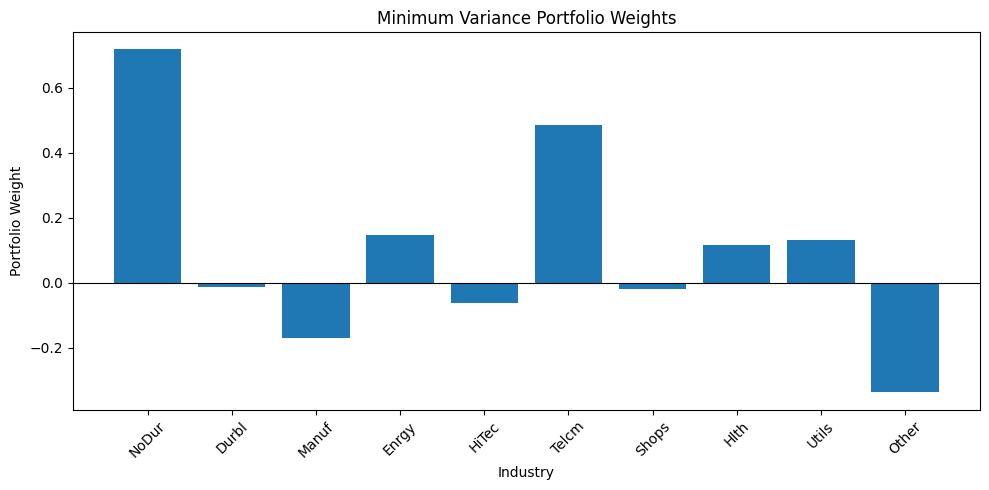

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(data.columns, w_min)

plt.axhline(y=0, color='black', linewidth=0.8)

plt.title("Minimum Variance Portfolio Weights")
plt.xlabel("Industry")
plt.ylabel("Portfolio Weight")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()